Task 1 - Data Preparation and Feature Engineering

In [1]:
# Task 1 | Cell 1: setup
import sys
import pandas as pd
import numpy as np
import yfinance as yf
import scipy
import sklearn

START = "2021-01-01"
END = "2025-01-01"
BASELINE = 20
WINDOW = 60
MULT = 2

RUN_DATE = pd.Timestamp.now().normalize()

print("Run date:", RUN_DATE.date())
print("Python:", sys.version.split()[0])
for name, mod in [("pandas", pd), ("numpy", np), ("yfinance", yf),
                  ("scipy", scipy), ("scikit-learn", sklearn)]:
    print(f"{name}: {mod.__version__}")

Run date: 2026-11-24
Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
yfinance: 0.2.66
scipy: 1.16.3
scikit-learn: 1.6.1


In [2]:
#Task 1.1 | Cell 2: S&P 500 ticker list

# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

tables = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500 = tables[0][["Symbol", "Security", "GICS Sector"]].copy()

sp500["Ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

sp500["Retrieved"] = RUN_DATE.date()

sp500.to_csv("sp500_tickers.csv", index=False)

tickers = sp500["Ticker"].tolist()
print("Retrieval date:", RUN_DATE.date())
print("Tickers extracted:", len(tickers))
print("Duplicate tickers:", sp500["Ticker"].duplicated().sum())
print("Sectors:", sp500["GICS Sector"].nunique())
sp500.head(10)

Retrieval date: 2026-11-24
Tickers extracted: 503
Duplicate tickers: 0
Sectors: 11


,Symbol,Security,GICS Sector,Ticker,Retrieved
0,MMM,3M,Industrials,MMM,2026-11-24
1,AOS,A. O. Smith,Industrials,AOS,2026-11-24
2,ABT,Abbott Laboratories,Health Care,ABT,2026-11-24
3,ABBV,AbbVie,Health Care,ABBV,2026-11-24
4,ACN,Accenture,Information Technology,ACN,2026-11-24
5,ADBE,Adobe Inc.,Information Technology,ADBE,2026-11-24
6,AMD,Advanced Micro Devices,Information Technology,AMD,2026-11-24
7,AES,AES Corporation,Utilities,AES,2026-11-24
8,AFL,Aflac,Financials,AFL,2026-11-24
9,A,Agilent Technologies,Health Care,A,2026-11-24


In [3]:
# Task 1.1 | Cell 3: download share and benchmark data

raw = yf.download(tickers, start=START, end=END,
                  auto_adjust=False, progress=False)

bench = yf.download("^GSPC", start=START, end=END,
                    auto_adjust=False, progress=False)

close = raw["Close"]
adj_close = raw["Adj Close"]
volume = raw["Volume"]

if isinstance(bench.columns, pd.MultiIndex):
    bench.columns = bench.columns.get_level_values(0)

print("Shares - dates x tickers:", close.shape)
print("First date:", close.index.min().date(), "| Last date:", close.index.max().date())
print("Benchmark rows:", bench.shape[0])

no_data = [t for t in tickers if t not in close.columns or close[t].isna().all()]
print("Tickers with no data:", len(no_data), no_data)

close.to_csv("raw_close.csv")
adj_close.to_csv("raw_adj_close.csv")
volume.to_csv("raw_volume.csv")
bench.to_csv("raw_gspc.csv")

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'SNDK', 'FDXF', 'Q', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shares - dates x tickers: (1005, 503)
First date: 2021-01-04 | Last date: 2024-12-31
Benchmark rows: 1005
Tickers with no data: 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [4]:
# task 1.2 - cell 4
exclusions = []

dup_dates = close.index.duplicated().sum()
print("Duplicate dates:", dup_dates)

print("Dates match benchmark:", close.index.equals(bench.index))

for t in tickers:

    if t not in close.columns or close[t].isna().all():
        exclusions.append({"ticker": t, "rule": "no data", "detail": "no Yahoo prices for the period"})
        continue

    first_valid = close[t].first_valid_index()
    late_start = first_valid > close.index[0]
    after_start = close[t].loc[first_valid:]
    interior_gaps = after_start.isna().sum()
    n_missing_adj = adj_close[t].isna().sum()
    n_missing_vol = volume[t].isna().sum()

    if late_start:
        exclusions.append({"ticker": t, "rule": "unequal history",
                           "detail": f"first valid date {first_valid.date()}"})
        continue
    if interior_gaps > 0 or n_missing_adj > 0 or n_missing_vol > 0:
        exclusions.append({"ticker": t, "rule": "data gaps",
                           "detail": f"close gaps={interior_gaps}, adj={n_missing_adj}, vol={n_missing_vol}"})
        continue

    n_zero_vol = (volume[t] == 0).sum()
    if n_zero_vol > 0:
        exclusions.append({"ticker": t, "rule": "zero volume days", "detail": f"{n_zero_vol} zero-volume days"})
        continue

    if (close[t] <= 0).any() or (adj_close[t] <= 0).any():
        min_p = min(close[t].min(), adj_close[t].min())
        exclusions.append({"ticker": t, "rule": "non-positive price", "detail": f"min_price={min_p}"})
        continue

    if (volume[t] < 0).any() or (volume[t] == 0).all():
        err_detail = "negative volume" if (volume[t] < 0).any() else "all volume zero"
        exclusions.append({"ticker": t, "rule": "volume error", "detail": err_detail})
        continue

exclusion_log = pd.DataFrame(exclusions)
if not exclusion_log.empty:
    print(exclusion_log["rule"].value_counts())
    display(exclusion_log)
else:
    print("No tickers excluded!")

valid_tickers = [t for t in tickers if t not in set(exclusion_log["ticker"])]
print("Valid tickers:", len(valid_tickers), "| Excluded:", len(exclusion_log))

Duplicate dates: 0
Dates match benchmark: True
rule
unequal history     10
no data              5
zero volume days     2
Name: count, dtype: int64


,ticker,rule,detail
0,APP,unequal history,first valid date 2021-04-15
1,COIN,unequal history,first valid date 2021-04-14
2,CEG,unequal history,first valid date 2022-01-19
3,EXE,unequal history,first valid date 2021-02-10
4,FDXF,no data,no Yahoo prices for the period
5,FERG,zero volume days,27 zero-volume days
6,GEHC,unequal history,first valid date 2022-12-15
7,GEV,unequal history,first valid date 2024-03-27
8,HONA,no data,no Yahoo prices for the period
9,Q,no data,no Yahoo prices for the period


Valid tickers: 486 | Excluded: 17


In [5]:
# Task 1.2 | Cell 5: Investigate zero-volume tickers & Save Log

for ticker in ['FERG', 'SW']:
    if ticker in volume.columns:
        zero_days = volume[ticker][volume[ticker] == 0].index
        if len(zero_days) > 0:
            print(f"{ticker}: {len(zero_days)} zero-volume days found.")
            print(f"  First zero day: {zero_days.min().date()} | Last zero day: {zero_days.max().date()}")
        else:
            print(f"{ticker}: No zero-volume days in active dataset (already excluded or not present).")

exclusion_log.to_csv("exclusion_log.csv", index=False)
print("\nSaved 'exclusion_log.csv' successfully.")

FERG: 27 zero-volume days found.
  First zero day: 2021-01-07 | Last zero day: 2021-03-05
SW: 424 zero-volume days found.
  First zero day: 2021-01-05 | Last zero day: 2024-07-05

Saved 'exclusion_log.csv' successfully.


In [6]:
# Task 1.2 | Cell 6: Corporate-action check
import pandas as pd
import numpy as np

close_pct = close[valid_tickers].pct_change(fill_method=None)

max_moves = close_pct.abs().max()

THRESHOLD = 0.40
large_moves_tickers = max_moves[max_moves > THRESHOLD].index.tolist()

print(f"Tickers with a >{THRESHOLD*100}% one-day Close move:", len(large_moves_tickers))

corporate_actions_suspects = []

for t in large_moves_tickers:

    extreme_date = close_pct[t].abs().idxmax()
    close_move = close_pct.loc[extreme_date, t]

    adj_close_pct = adj_close[t].pct_change(fill_method=None)
    adj_close_move = adj_close_pct.loc[extreme_date]

    ratio_before = adj_close.loc[:extreme_date, t].iloc[-2] / close.loc[:extreme_date, t].iloc[-2] if len(close.loc[:extreme_date, t]) > 1 else np.nan
    ratio_after = adj_close.loc[extreme_date:, t].iloc[0] / close.loc[extreme_date:, t].iloc[0]

    corporate_actions_suspects.append({
        "Ticker": t,
        "Date": extreme_date.date(),
        "Close Move": f"{close_move:.2%}",
        "Adj Close Move": f"{adj_close_move:.2%}",
        "Ratio Before (Adj/Close)": f"{ratio_before:.4f}",
        "Ratio After (Adj/Close)": f"{ratio_after:.4f}",
        "Split Likely": abs(adj_close_move) < 0.05 and abs(close_move) > THRESHOLD
    })

corp_df = pd.DataFrame(corporate_actions_suspects)
if not corp_df.empty:
    display(corp_df)
else:
    print("No tickers exceeded the daily change threshold.")

Tickers with a >40.0% one-day Close move: 4


,Ticker,Date,Close Move,Adj Close Move,Ratio Before (Adj/Close),Ratio After (Adj/Close),Split Likely
0,BE,2024-11-15,59.19%,59.19%,1.0000,1.0000,False
1,CVNA,2023-06-08,56.02%,56.02%,1.0000,1.0000,False
2,DXCM,2024-07-26,-40.66%,-40.66%,1.0000,1.0000,False
3,GL,2024-04-11,-53.14%,-53.14%,0.9785,0.9785,False


In [7]:
# Task 1.2 | Cell 7

nvda_split_window = pd.DataFrame({
    "Close": close["NVDA"],
    "Adj Close": adj_close["NVDA"],
    "Adj/Close ratio": adj_close["NVDA"] / close["NVDA"],
    "Volume": volume["NVDA"],
}).loc["2024-06-05":"2024-06-12"]
display(nvda_split_window)

known_splits = {"AMZN": "2022-06-06", "GOOGL": "2022-07-18", "TSLA": "2022-08-25",
                "WMT": "2024-02-26", "CMG": "2024-06-26", "NVDA": "2024-06-10",
                "AVGO": "2024-07-15"}

rows = []
for t, d in known_splits.items():
    if t in close.columns:
        move = close[t].pct_change(fill_method=None).get(pd.Timestamp(d))
        rows.append({"Ticker": t, "Split date": d, "One-day Close move": f"{move:.2%}"})
display(pd.DataFrame(rows))

print("Conclusion: Close and Volume are already split-adjusted, so Close x Volume "
      "(Monetary) is on a consistent basis. The Adj/Close ratio only reflects dividends.")

,Close,Adj Close,Adj/Close ratio,Volume
Date,,,,
2024-06-05,122.440002,122.091873,0.997157,528402000
2024-06-06,120.998001,120.653969,0.997157,664696000
2024-06-07,120.888000,120.544289,0.997157,412386000
2024-06-10,121.790001,121.443718,0.997157,313434100
2024-06-11,120.910004,120.576126,0.997239,222551200
2024-06-12,125.199997,124.854279,0.997239,299595000


,Ticker,Split date,One-day Close move
0,AMZN,2022-06-06,1.99%
1,GOOGL,2022-07-18,-2.46%
2,TSLA,2022-08-25,-0.35%
3,WMT,2024-02-26,1.85%
4,CMG,2024-06-26,0.30%
5,NVDA,2024-06-10,0.75%
6,AVGO,2024-07-15,0.80%


Conclusion: Close and Volume are already split-adjusted, so Close x Volume (Monetary) is on a consistent basis. The Adj/Close ratio only reflects dividends.


In [8]:
# Task 1.3.1 | Cell 8: Mean Weekly Return

import pandas as pd
import numpy as np

prices = adj_close[valid_tickers]
bench_px = bench["Adj Close"]

if isinstance(bench_px, pd.DataFrame):
    bench_px = bench_px.iloc[:, 0]

weekly_px = prices.resample("W-FRI").last()
weekly_bench = bench_px.resample("W-FRI").last()

days_per_week = prices.resample("W-FRI").count()

print("Trading days in the first 3 weeks of the dataset:")
print(days_per_week.iloc[:3, 0])

print("\nTrading days in the last 3 weeks of the dataset:")
print(days_per_week.iloc[-3:, 0])

weekly_px = weekly_px.drop(pd.Timestamp("2025-01-03"), errors="ignore")
weekly_bench = weekly_bench.drop(pd.Timestamp("2025-01-03"), errors="ignore")

weekly_ret = weekly_px.pct_change(fill_method=None)
weekly_bench_ret = weekly_bench.pct_change(fill_method=None)

weekly_ret = weekly_ret.dropna(how="all")
weekly_bench_ret = weekly_bench_ret.dropna()

weekly_ret, weekly_bench_ret = weekly_ret.align(
    weekly_bench_ret, join="inner", axis=0
)

assert weekly_ret.index.equals(weekly_bench_ret.index), "Index mismatch!"

mean_ret = weekly_ret.mean()

print("\nMean weekly returns:")
display(mean_ret.describe())

Trading days in the first 3 weeks of the dataset:
Date
2021-01-08    5
2021-01-15    5
2021-01-22    4
Freq: W-FRI, Name: MMM, dtype: int64

Trading days in the last 3 weeks of the dataset:
Date
2024-12-20    5
2024-12-27    4
2025-01-03    2
Freq: W-FRI, Name: MMM, dtype: int64

Mean weekly returns:


,0
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


In [9]:
# Task 1.3.2 | Cell 9: Weekly Beta

cov_matrix = weekly_ret.apply(
    lambda x: x.cov(weekly_bench_ret)
)

bench_var = weekly_bench_ret.var()

beta = cov_matrix / bench_var

n_weeks = weekly_ret.apply(
    lambda x: x.notna().mul(weekly_bench_ret.notna()).sum()
)

print("\nWeekly Beta:")
display(beta.describe())

print("\nNumber of aligned weekly observations:")
print(n_weeks.unique())


Weekly Beta:


,0
count,486.000000
mean,0.973695
std,0.407339
min,0.055453
25%,0.666600
50%,0.950609
75%,1.179538
max,3.778560



Number of aligned weekly observations:
[207]


In [10]:
# Task 1.3 | Cell 10: Combined Returns Features

returns_features = pd.DataFrame({
    "mean_weekly_return": mean_ret,
    "beta": beta,
    "n_weeks": n_weeks
})

print("\nSummary statistics of returns features:")
display(returns_features.describe())

print("\nAligned weekly observations:")
print(n_weeks.unique())

returns_features.to_csv("weekly_features.csv")

print("\nWeekly features successfully saved!")


Summary statistics of returns features:


,mean_weekly_return,beta,n_weeks
count,486.000000,486.000000,486.0
mean,0.002857,0.973695,207.0
std,0.002652,0.407339,0.0
min,-0.004468,0.055453,207.0
25%,0.001182,0.666600,207.0
50%,0.002619,0.950609,207.0
75%,0.004207,1.179538,207.0
max,0.017772,3.778560,207.0



Aligned weekly observations:
[207]

Weekly features successfully saved!


In [11]:
#  Task 1.4 | Cell 11: RFM setup

vol = volume[valid_tickers]
px  = close[valid_tickers]

obs_date = close.index.max()
print("Observation date:", obs_date.date())

baseline = vol.shift(1).rolling(window=BASELINE).mean()

threshold = MULT * baseline

testable = baseline.notna() & vol.notna()

hv_flag = (vol > threshold) & testable

assert (hv_flag & ~testable).sum().sum() == 0

print("Shares:", hv_flag.shape[1], "| flagged days in total:", int(hv_flag.sum().sum()))
print("All shares have >= 80 sessions:", (vol.notna().sum() >= BASELINE + WINDOW).all())

Observation date: 2024-12-31
Shares: 486 | flagged days in total: 18280
All shares have >= 80 sessions: True


In [12]:
# Task 1.4.1 | Cell 12: Recency

recency = {}

for t in hv_flag.columns:

    flagged_dates = hv_flag.index[hv_flag[t] & (hv_flag.index <= obs_date)]

    if len(flagged_dates) == 0:
        recency[t] = np.nan
    else:
        recency[t] = (obs_date - flagged_dates[-1]).days

recency = pd.Series(recency, name="R")

print("Shares with no event (R missing):", recency.isna().sum())

# Rule applied: no-event shares would be excluded (R left as NaN, never 0). Result: 0 shares excluded.

Shares with no event (R missing): 0


In [13]:
# Task 1.4.2 | Cell 13: Frequency

last60 = vol.loc[:obs_date].tail(WINDOW)

assert len(last60) == WINDOW
assert last60.index[-1] == obs_date

frequency = hv_flag.loc[last60.index].sum(axis=0)

frequency.name = "F"

print(frequency.describe())

count    486.000000
mean       2.989712
std        1.330800
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
Name: F, dtype: float64


In [14]:
# Task 1.4.3 | Cell 14: Monetary

daily_value = px * vol

monetary = daily_value.loc[last60.index].sum(axis=0)

monetary.name = "M"

print(monetary.describe())

count    4.860000e+02
mean     3.940419e+10
std      1.291388e+11
min      1.297483e+09
25%      1.019517e+10
50%      1.668382e+10
75%      3.227689e+10
max      1.847697e+12
Name: M, dtype: float64


In [15]:
# Task 1.4 - Combine R, F and M

rfm = pd.concat([recency, frequency, monetary], axis=1)

print("\nRFM feature table:")
display(rfm.head())

print("\nRFM summary:")
display(rfm.describe())


RFM feature table:


,R,F,M
MMM,11,4,2.599146e+10
AOS,11,2,4.748980e+09
ABT,11,1,3.523027e+10
ABBV,11,3,6.837054e+10
ACN,11,2,5.199430e+10



RFM summary:


,R,F,M
count,486.000000,486.000000,4.860000e+02
mean,20.407407,2.989712,3.940419e+10
std,21.342438,1.330800,1.291388e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.019517e+10
50%,11.000000,3.000000,1.668382e+10
75%,14.750000,4.000000,3.227689e+10
max,222.000000,8.000000,1.847697e+12


In [16]:

# Task 1.5 | Cell 16: Investigate shared Recency values

print("Most common Recency values:")
print(recency.value_counts().head())

date_11_days_before = obs_date - pd.Timedelta(days=11)

print("\nDate 11 days before observation date:", date_11_days_before.date())

check_date = pd.Timestamp("2024-12-20")

if check_date in hv_flag.index:
    flagged_share = hv_flag.loc[check_date].mean()

    print("\nShares flagged on 2024-12-20:")
    print("Number of shares:", int(hv_flag.loc[check_date].sum()))
    print("Percentage of shares:", round(flagged_share * 100, 2), "%")
else:
    print("\n2024-12-20 is not available in the trading date index.")


Most common Recency values:
R
11    353
36     17
55     11
60      6
46      6
Name: count, dtype: int64

Date 11 days before observation date: 2024-12-20

Shares flagged on 2024-12-20:
Number of shares: 354
Percentage of shares: 72.84 %


In [17]:

# Task 1.5 | Cell 17: AAPL Worked Example

ticker = "AAPL"

if ticker not in vol.columns:
    raise ValueError("AAPL is not available in the valid ticker dataset.")

aapl_example = pd.DataFrame({
    "Volume": vol[ticker],
    "Baseline": baseline[ticker],
    "Threshold": threshold[ticker],
    "High_Volume_Flag": hv_flag[ticker]
})

aapl_example = aapl_example.loc[:obs_date].tail(10)

print("AAPL - Last 10 Trading Sessions:")
display(aapl_example)

aapl_flagged_dates = hv_flag.index[
    hv_flag[ticker] & (hv_flag.index <= obs_date)
]

if len(aapl_flagged_dates) > 0:
    latest_event = aapl_flagged_dates[-1]
    aapl_R = (obs_date - latest_event).days
else:
    latest_event = pd.NaT
    aapl_R = np.nan

aapl_F = int(hv_flag.loc[last60.index, ticker].sum())

aapl_daily_value = (
    px.loc[last60.index, ticker] *
    vol.loc[last60.index, ticker]
)

aapl_M = aapl_daily_value.sum()

print("\nAAPL Worked RFM Calculations")

print("Observation date:", obs_date.date())
print("Latest qualifying event:",
      latest_event.date() if pd.notna(latest_event) else "No event")

print("Recency (R):", aapl_R)
print("Frequency (F):", aapl_F)
print("Monetary (M):", f"${aapl_M:,.2f}")

print("\nComparison with RFM table:")

aapl_comparison = pd.DataFrame({
    "Calculated": [aapl_R, aapl_F, aapl_M],
    "RFM Table": [
        rfm.loc[ticker, "R"],
        rfm.loc[ticker, "F"],
        rfm.loc[ticker, "M"]
    ]
}, index=["R", "F", "M"])

display(aapl_comparison)

assert np.isclose(aapl_R, rfm.loc[ticker, "R"], equal_nan=True)
assert np.isclose(aapl_F, rfm.loc[ticker, "F"])
assert np.isclose(aapl_M, rfm.loc[ticker, "M"])

print("AAPL worked example matches the RFM table.")


AAPL - Last 10 Trading Sessions:


,Volume,Baseline,Threshold,High_Volume_Flag
Date,,,,
2024-12-17,51356400,42354720.0,84709440.0,False
2024-12-18,56774100,42690855.0,85381710.0,False
2024-12-19,60882300,43718970.0,87437940.0,False
2024-12-20,147495300,45004605.0,90009210.0,True
2024-12-23,40858800,50273955.0,100547910.0,False
2024-12-24,23234700,50408480.0,100816960.0,False
2024-12-26,27237100,47062575.0,94125150.0,False
2024-12-27,42355300,46125120.0,92250240.0,False
2024-12-30,35557500,46567965.0,93135930.0,False



AAPL Worked RFM Calculations
Observation date: 2024-12-31
Latest qualifying event: 2024-12-20
Recency (R): 11
Frequency (F): 2
Monetary (M): $623,303,377,706.58

Comparison with RFM table:


,Calculated,RFM Table
R,1.100000e+01,1.100000e+01
F,2.000000e+00,2.000000e+00
M,6.233034e+11,6.233034e+11


AAPL worked example matches the RFM table.


In [18]:

# Task 1.5 | Cell 18: Validation Summary

print("=" * 55)
print("TASK 1.5 - VALIDATION SUMMARY")
print("=" * 55)

print("\nExclusion counts by rule:")
print(exclusion_log["rule"].value_counts())

print("\nNumber of valid shares:", len(valid_tickers))

print("\nRecency (R) Summary:")
print(recency.describe())

print("\nFrequency (F) Summary:")
print(frequency.describe())

print("\nMonetary (M) Summary:")
print(monetary.describe())

print("\nMissing values in RFM:")
print(rfm.isna().sum())

print("\nShares with complete RFM:", len(rfm.dropna()))

print("\nValidation summary completed.")

TASK 1.5 - VALIDATION SUMMARY

Exclusion counts by rule:
rule
unequal history     10
no data              5
zero volume days     2
Name: count, dtype: int64

Number of valid shares: 486

Recency (R) Summary:
count    486.000000
mean      20.407407
std       21.342438
min        4.000000
25%       11.000000
50%       11.000000
75%       14.750000
max      222.000000
Name: R, dtype: float64

Frequency (F) Summary:
count    486.000000
mean       2.989712
std        1.330800
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
Name: F, dtype: float64

Monetary (M) Summary:
count    4.860000e+02
mean     3.940419e+10
std      1.291388e+11
min      1.297483e+09
25%      1.019517e+10
50%      1.668382e+10
75%      3.227689e+10
max      1.847697e+12
Name: M, dtype: float64

Missing values in RFM:
R    0
F    0
M    0
dtype: int64

Shares with complete RFM: 486

Validation summary completed.


In [19]:
# Task 1.5 | Cell 19: Final feature table (one row per included share)

sector_df = (sp500[["Ticker", "GICS Sector"]]
             .rename(columns={"GICS Sector": "Sector"})
             .set_index("Ticker"))

weekly_df = returns_features.rename(columns={"mean_weekly_return": "Mean_Weekly_Return",
                                             "beta": "Beta"})
weekly_df.index.name = "Ticker"
rfm.index.name = "Ticker"

assert sector_df.index.is_unique and weekly_df.index.is_unique and rfm.index.is_unique

feature_table = (sector_df.loc[valid_tickers]
                 .join(weekly_df, how="inner")
                 .join(rfm, how="inner"))

assert len(feature_table) == len(valid_tickers), "Shares lost in the join"
assert not feature_table.isna().any().any(), "Missing values in feature table"

print("Final feature table shape:", feature_table.shape)
display(feature_table.head())
feature_table.to_csv("feature_table.csv")

Final feature table shape: (486, 7)


,Sector,Mean_Weekly_Return,Beta,n_weeks,R,F,M
Ticker,,,,,,,
MMM,Industrials,0.001142,0.869079,207,11,4,2.599146e+10
AOS,Industrials,0.001991,1.042805,207,11,2,4.748980e+09
ABT,Health Care,0.000971,0.583543,207,11,1,3.523027e+10
ABBV,Health Care,0.003749,0.425365,207,11,3,6.837054e+10
ACN,Information Technology,0.002376,1.143300,207,11,2,5.199430e+10


Task 2 - Stock Segmentation and Sensitivity Analysis

Original feature skewness:
Mean_Weekly_Return     0.867516
Beta                   1.103649
R                      3.645784
F                      0.424735
M                     11.683797
dtype: float64


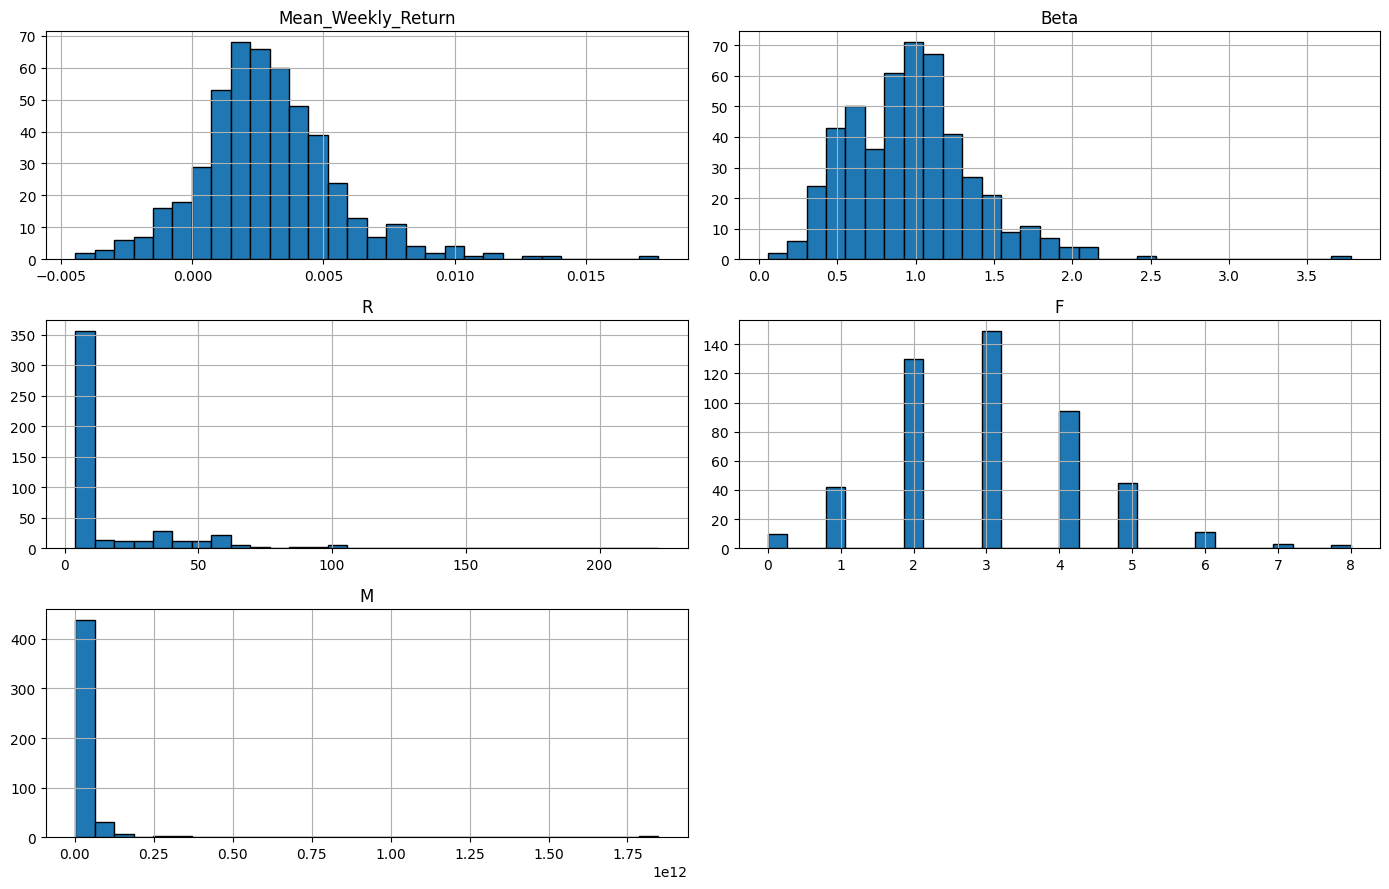


Outlier counts (1.5 x IQR rule):
Mean_Weekly_Return : 15
Beta : 10
R : 115
F : 2
M : 45

Monetary skewness before transformation: 11.683796873806312
Monetary skewness after log1p transformation: 1.0790573618432242

Recency skewness before transformation: 3.645784052628137
Recency skewness after log1p transformation: 1.5832014581917597


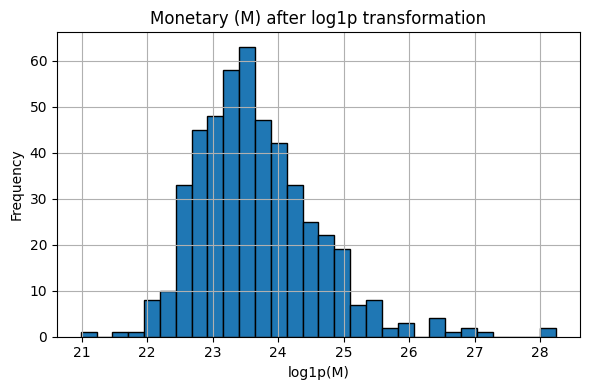

In [20]:

# Task 2.1 | Cell 20: skew and outlier inspection
import matplotlib.pyplot as plt

cols = ["Mean_Weekly_Return", "Beta", "R", "F", "M"]

print("Original feature skewness:")
print(feature_table[cols].skew())

# Histograms of the five original features
feature_table[cols].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

# Count outliers using the 1.5 x IQR rule
print("\nOutlier counts (1.5 x IQR rule):")

for col in cols:
    Q1 = feature_table[col].quantile(0.25)
    Q3 = feature_table[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (feature_table[col] < lower) |
        (feature_table[col] > upper)
    )

    print(col, ":", outliers.sum())

# Apply log1p to Monetary and check skewness again
log_M = np.log1p(feature_table["M"])

print("\nMonetary skewness before transformation:",
      feature_table["M"].skew())

print("Monetary skewness after log1p transformation:",
      log_M.skew())

# Apply log1p to Recency and check skewness again
log_R = np.log1p(feature_table["R"])

print("\nRecency skewness before transformation:",
      feature_table["R"].skew())

print("Recency skewness after log1p transformation:",
      log_R.skew())

# Histogram after log1p transformation
log_M.hist(figsize=(6, 4), bins=30, edgecolor="black")
plt.title("Monetary (M) after log1p transformation")
plt.xlabel("log1p(M)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [21]:

# Task 2.1 | Cell 21: feature matrices

X_rr = feature_table[["Mean_Weekly_Return", "Beta"]].copy()

X_rfm = feature_table[["R", "F", "M"]].copy()

# Apply log1p to Monetary
X_rfm["M"] = np.log1p(X_rfm["M"])

# Apply log1p to Recency
X_rfm["R"] = np.log1p(X_rfm["R"])


assert X_rr.index.equals(X_rfm.index)

print("Risk and Return matrix shape:", X_rr.shape)
print("RFM matrix shape:", X_rfm.shape)
print("\nSkewness of RFM inputs after transformation:")
print(X_rfm.skew())

Risk and Return matrix shape: (486, 2)
RFM matrix shape: (486, 3)

Skewness of RFM inputs after transformation:
R    1.583201
F    0.424735
M    1.079057
dtype: float64


In [22]:

# Task 2.1 | Cell 22: standardisation

from sklearn.preprocessing import StandardScaler

scaler_rr = StandardScaler()
scaler_rfm = StandardScaler()

Z_rr = pd.DataFrame(
    scaler_rr.fit_transform(X_rr),
    index=X_rr.index,
    columns=X_rr.columns
)

Z_rfm = pd.DataFrame(
    scaler_rfm.fit_transform(X_rfm),
    index=X_rfm.index,
    columns=X_rfm.columns
)

print("Risk and Return - Mean:")
print(Z_rr.mean().round(2))

print("\nRisk and Return - Standard Deviation:")
print(Z_rr.std(ddof=0).round(2))

print("\nRFM - Mean:")
print(Z_rfm.mean().round(2))

print("\nRFM - Standard Deviation:")
print(Z_rfm.std(ddof=0).round(2))


Risk and Return - Mean:
Mean_Weekly_Return   -0.0
Beta                  0.0
dtype: float64

Risk and Return - Standard Deviation:
Mean_Weekly_Return    1.0
Beta                  1.0
dtype: float64

RFM - Mean:
R    0.0
F   -0.0
M   -0.0
dtype: float64

RFM - Standard Deviation:
R    1.0
F    1.0
M    1.0
dtype: float64


In [23]:

# Task 2.2 | Cell 23: Ward linkage

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

# Apply Ward linkage to each standardised feature matrix
link_rr = linkage(Z_rr, method="ward")
link_rfm = linkage(Z_rfm, method="ward")

print("Risk and Return linkage shape:", link_rr.shape)
print("RFM linkage shape:", link_rfm.shape)


Risk and Return linkage shape: (485, 4)
RFM linkage shape: (485, 4)


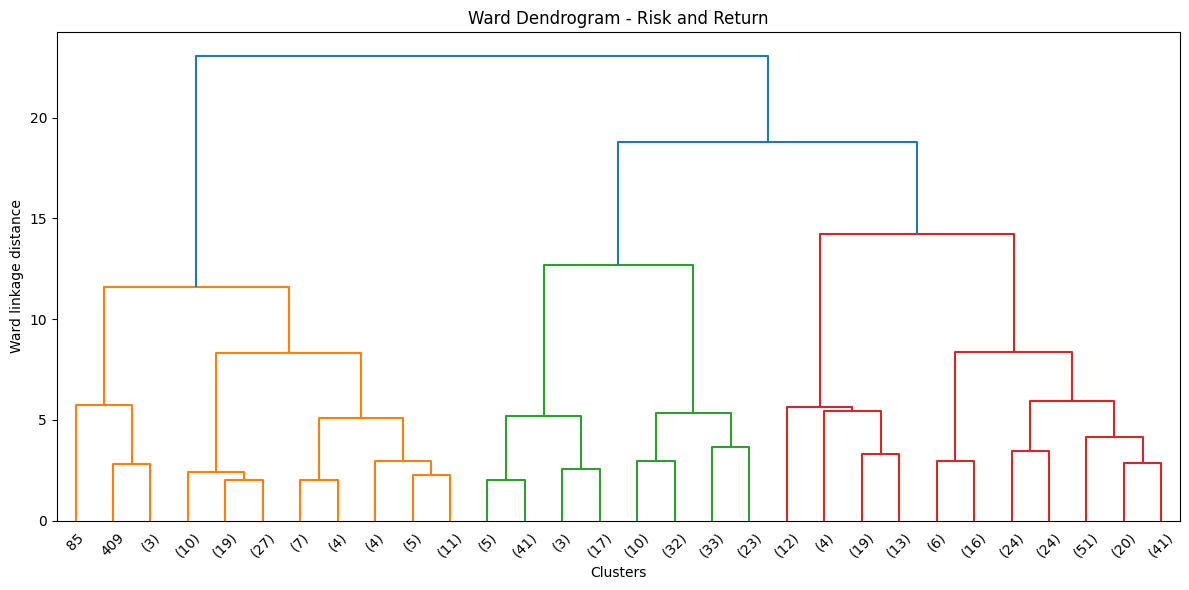

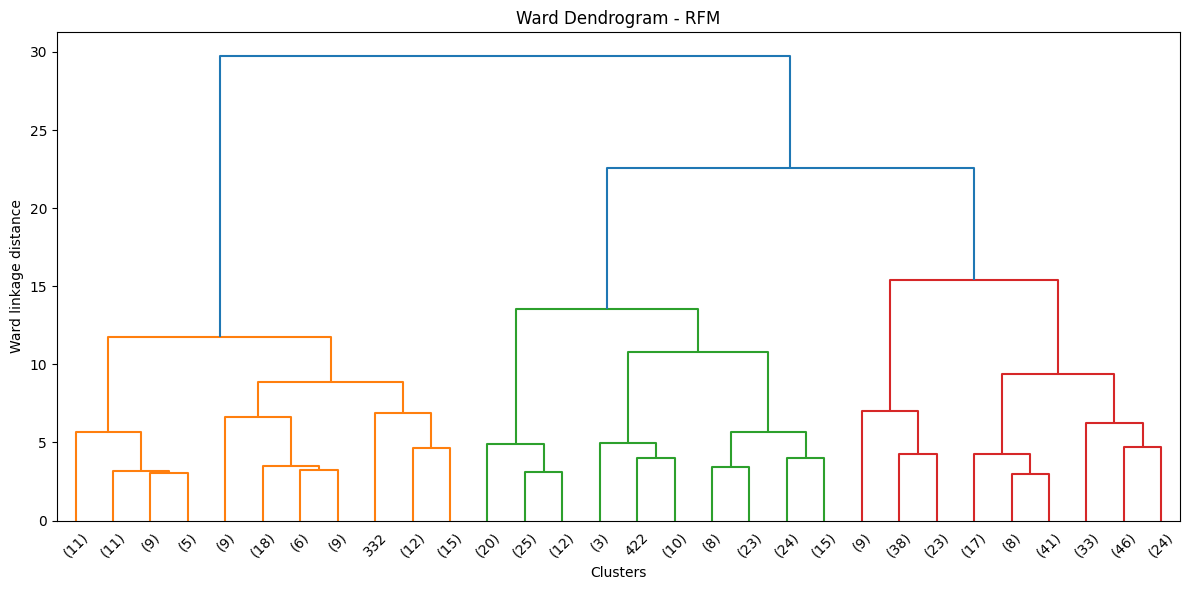

In [24]:

# Task 2.2 | Cell 24: dendrograms

import matplotlib.pyplot as plt

# Risk and Return dendrogram
plt.figure(figsize=(12, 6))
dendrogram(
    link_rr,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title("Ward Dendrogram - Risk and Return")
plt.xlabel("Clusters")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

# RFM dendrogram
plt.figure(figsize=(12, 6))
dendrogram(
    link_rfm,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title("Ward Dendrogram - RFM")
plt.xlabel("Clusters")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()


Risk and Return diagnostics:


,k,silhouette,sizes,smallest
0,2,0.339485,"[394, 92]",92
1,3,0.273834,"[230, 164, 92]",92
2,4,0.282115,"[182, 164, 48, 92]",48
3,5,0.304135,"[182, 66, 98, 48, 92]",48
4,6,0.320409,"[182, 66, 98, 48, 87, 5]",5
5,7,0.323951,"[160, 66, 98, 48, 22, 87, 5]",5
6,8,0.320779,"[160, 66, 98, 48, 22, 56, 31, 5]",5


RFM diagnostics:


,k,silhouette,sizes,smallest
0,2,0.402044,"[380, 106]",106
1,3,0.335170,"[141, 239, 106]",106
2,4,0.292533,"[141, 169, 106, 70]",70
3,5,0.285990,"[84, 169, 57, 106, 70]",57
4,6,0.276030,"[84, 169, 57, 36, 70, 70]",36
5,7,0.296944,"[70, 169, 57, 14, 36, 70, 70]",14
6,8,0.299019,"[70, 66, 57, 14, 36, 70, 70, 103]",14


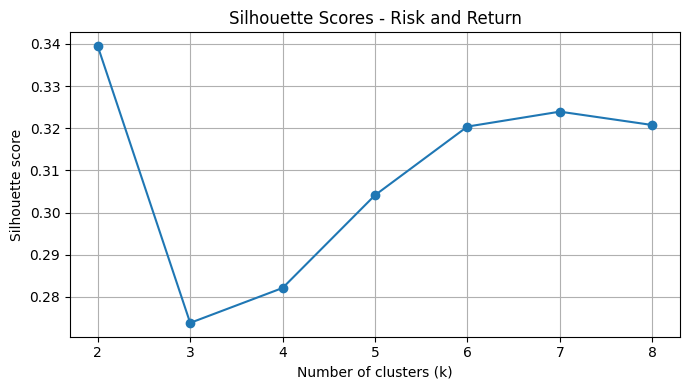

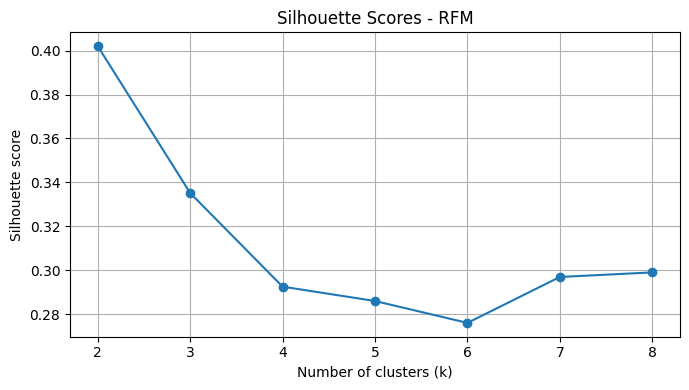

In [25]:

# Task 2.2 | Cell 25: silhouette, sizes for k = 2..8

def ward_diagnostics(link, Z_data, k_range=range(2, 9)):
    rows = []

    for k in k_range:
        labels = cut_tree(link, n_clusters=k).ravel().astype(int)

        sil = silhouette_score(Z_data, labels)

        sizes = np.bincount(labels)

        rows.append({
            "k": k,
            "silhouette": sil,
            "sizes": sizes.tolist(),
            "smallest": sizes.min()
        })

    return pd.DataFrame(rows)

diag_rr = ward_diagnostics(link_rr, Z_rr)
diag_rfm = ward_diagnostics(link_rfm, Z_rfm)

print("Risk and Return diagnostics:")
display(diag_rr)

print("RFM diagnostics:")
display(diag_rfm)


plt.figure(figsize=(7, 4))
plt.plot(diag_rr["k"], diag_rr["silhouette"], marker="o")
plt.title("Silhouette Scores - Risk and Return")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(diag_rfm["k"], diag_rfm["silhouette"], marker="o")
plt.title("Silhouette Scores - RFM")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()


In [26]:

# Task 2.2 | Cell 26: profiles in original units

def show_ward_profiles(link, original_data, candidate_ks, features, title, small=20):

    for k in candidate_ks:

        labels = cut_tree(link, n_clusters=k).ravel().astype(int)

        profile_data = original_data[features].copy()
        profile_data["Cluster"] = labels

        print("\n" + "=" * 55)
        print(title, "- k =", k)
        print("=" * 55)

        print("\nCluster sizes:")
        print(profile_data["Cluster"].value_counts().sort_index())


        print("\nCluster profiles (mean):")
        display(profile_data.groupby("Cluster")[features].mean().round(4))

        print("Cluster profiles (median):")
        display(profile_data.groupby("Cluster")[features].median().round(4))


        sizes = profile_data["Cluster"].value_counts()
        for c in sizes[sizes <= small].index:
            members = profile_data.index[profile_data["Cluster"] == c].tolist()
            print(f"Small cluster {c} ({len(members)} shares):", members)



extra_rr = []
extra_rfm = []

candidate_ks_rr = sorted(set(diag_rr.nlargest(3, "silhouette")["k"].tolist() + extra_rr))
candidate_ks_rfm = sorted(set(diag_rfm.nlargest(3, "silhouette")["k"].tolist() + extra_rfm))

print("Risk and Return candidate k values:", candidate_ks_rr)
show_ward_profiles(link_rr, feature_table, candidate_ks_rr,
                   ["Mean_Weekly_Return", "Beta"], "Risk and Return")

print("\nRFM candidate k values:", candidate_ks_rfm)
show_ward_profiles(link_rfm, feature_table, candidate_ks_rfm,
                   ["R", "F", "M"], "RFM")

Risk and Return candidate k values: [2, 7, 8]

Risk and Return - k = 2

Cluster sizes:
Cluster
0    394
1     92
Name: count, dtype: int64

Cluster profiles (mean):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0020,0.8979
1,0.0063,1.2981


Cluster profiles (median):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0021,0.8817
1,0.0055,1.2177



Risk and Return - k = 7

Cluster sizes:
Cluster
0    160
1     66
2     98
3     48
4     22
5     87
6      5
Name: count, dtype: int64

Cluster profiles (mean):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0017,0.9499
1,0.0009,0.4390
2,0.0042,0.7104
3,0.0020,1.6280
4,-0.0016,1.1397
5,0.0059,1.2383
6,0.0129,2.3386


... (15 outputs left out)

,R,F,M
Cluster,,,
0,12.0143,3.6000,5.040407e+10
1,11.0758,1.8636,1.085987e+10
2,11.0000,1.7193,4.240849e+10
3,16.4286,4.5714,4.255684e+11
4,38.7778,3.6944,1.570820e+10
5,59.4571,1.7286,5.558168e+10
6,11.0571,4.6857,1.471939e+10
7,11.2330,3.2427,1.013192e+10


Cluster profiles (median):


,R,F,M
Cluster,,,
0,11.0,3.0,4.460450e+10
1,11.0,2.0,1.067576e+10
2,11.0,2.0,3.236510e+10
3,11.0,5.0,3.037731e+11
4,36.0,3.0,1.490924e+10
5,55.0,2.0,2.502932e+10
6,11.0,4.0,1.376417e+10
7,11.0,3.0,8.851100e+09


Small cluster 3 (14 shares): ['AMD', 'GOOGL', 'GOOG', 'AMZN', 'AAPL', 'BA', 'AVGO', 'LLY', 'META', 'MSFT', 'PLTR', 'SMCI', 'TSLA', 'UNH']


In [27]:
# Task 2.2 | Cell 27: store the chosen Ward solutions
k_rr_ward  = 7
k_rfm_ward = 8

feature_table["Ward_RR"]  = cut_tree(link_rr,  n_clusters=k_rr_ward).ravel()
feature_table["Ward_RFM"] = cut_tree(link_rfm, n_clusters=k_rfm_ward).ravel()
print(feature_table[["Ward_RR", "Ward_RFM"]].nunique())
feature_table.to_csv("feature_table.csv")

Ward_RR     7
Ward_RFM    8
dtype: int64


In [28]:
# Task 2.3 | Cell 28: K-means for k = 2..8
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
N_INIT = 10

def kmeans_diagnostics(Z_data, k_range=range(2, 9)):
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit(Z_data)
        labels = km.labels_
        sil = silhouette_score(Z_data, labels)
        sizes = np.bincount(labels)
        rows.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": sil,
            "sizes": sizes.tolist(),
            "smallest": sizes.min()
        })
    return pd.DataFrame(rows)

diag_km_rr  = kmeans_diagnostics(Z_rr)
diag_km_rfm = kmeans_diagnostics(Z_rfm)

print("K-means Risk & Return Diagnostics:")
display(diag_km_rr)

print("\nK-means RFM Diagnostics:")
display(diag_km_rfm)

K-means Risk & Return Diagnostics:


,k,inertia,silhouette,sizes,smallest
0,2,621.634364,0.386950,"[143, 343]",143
1,3,461.184986,0.328619,"[202, 120, 164]",120
2,4,371.577054,0.326978,"[132, 154, 40, 160]",40
3,5,309.613060,0.340589,"[112, 166, 131, 27, 50]",27
4,6,265.707196,0.326443,"[115, 20, 85, 134, 56, 76]",20
5,7,227.476238,0.331472,"[83, 74, 143, 85, 5, 48, 48]",5
6,8,195.951745,0.352669,"[143, 81, 82, 5, 77, 36, 34, 28]",5



K-means RFM Diagnostics:


,k,inertia,silhouette,sizes,smallest
0,2,999.520393,0.415400,"[384, 102]",102
1,3,742.493330,0.343037,"[257, 139, 90]",90
2,4,559.243771,0.361713,"[82, 194, 90, 120]",82
3,5,480.744042,0.348176,"[141, 87, 40, 99, 119]",40
4,6,421.194173,0.344619,"[139, 31, 38, 96, 113, 69]",31
5,7,377.817732,0.339791,"[87, 31, 44, 68, 147, 89, 20]",20
6,8,346.959256,0.321646,"[64, 83, 56, 35, 104, 82, 19, 43]",19


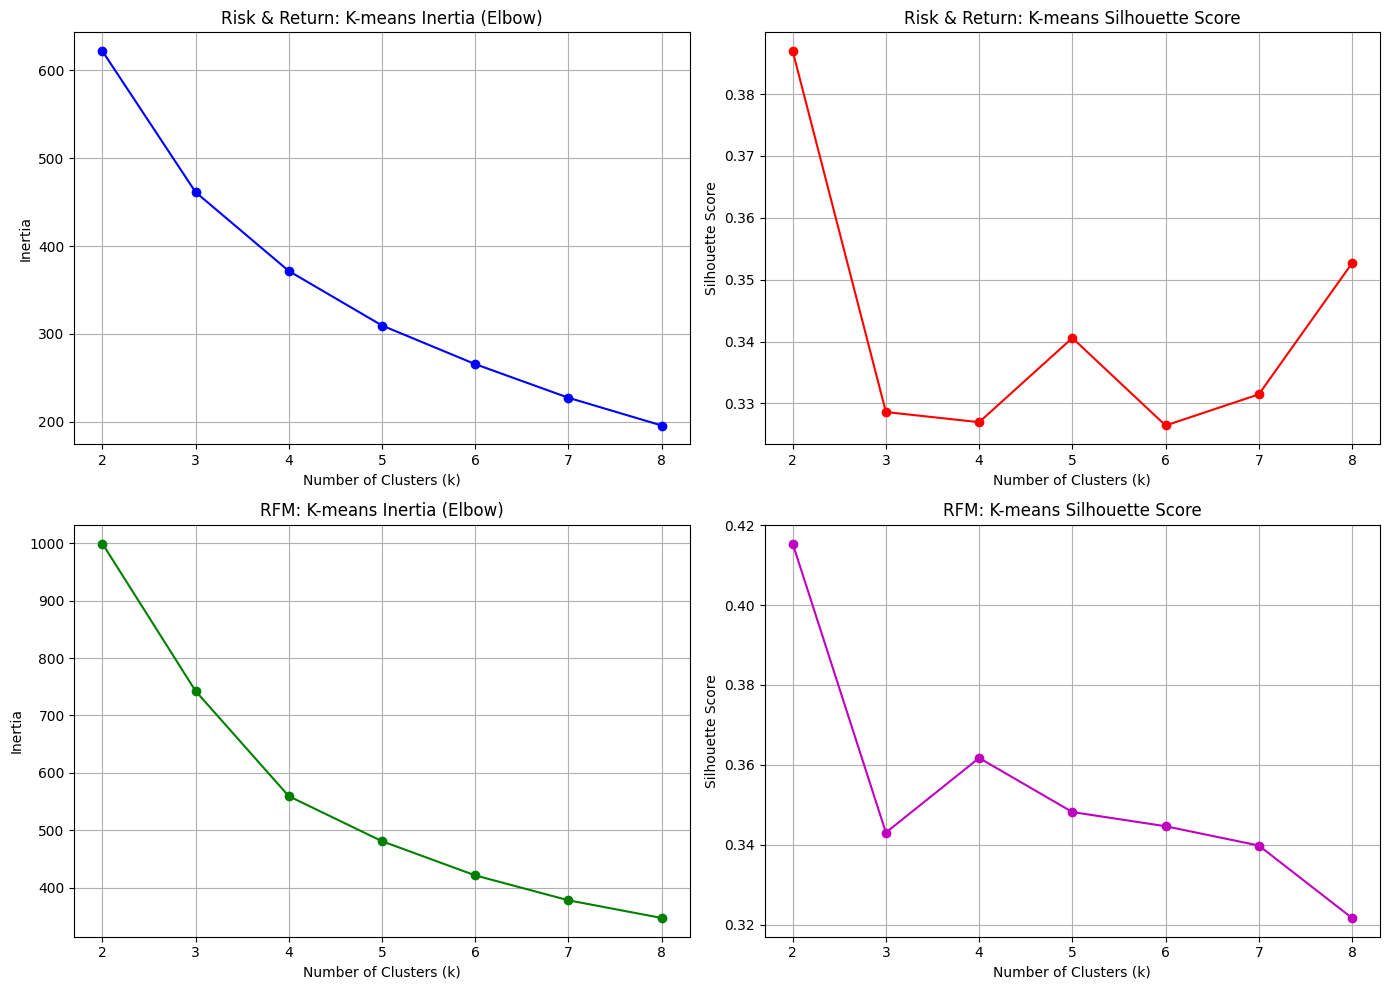

In [29]:
# Task 2.3 | Cell 29: Elbow and Silhouette Plots
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Risk & Return Plots
# Elbow
axes[0, 0].plot(diag_km_rr["k"], diag_km_rr["inertia"], marker="o", color="b", linestyle="-")
axes[0, 0].set_title("Risk & Return: K-means Inertia (Elbow)")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].set_xticks(range(2, 9))
axes[0, 0].grid(True)

# Silhouette
axes[0, 1].plot(diag_km_rr["k"], diag_km_rr["silhouette"], marker="o", color="r", linestyle="-")
axes[0, 1].set_title("Risk & Return: K-means Silhouette Score")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].set_xticks(range(2, 9))
axes[0, 1].grid(True)

# RFM Plots
# Elbow
axes[1, 0].plot(diag_km_rfm["k"], diag_km_rfm["inertia"], marker="o", color="g", linestyle="-")
axes[1, 0].set_title("RFM: K-means Inertia (Elbow)")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Inertia")
axes[1, 0].set_xticks(range(2, 9))
axes[1, 0].grid(True)

# Silhouette
axes[1, 1].plot(diag_km_rfm["k"], diag_km_rfm["silhouette"], marker="o", color="m", linestyle="-")
axes[1, 1].set_title("RFM: K-means Silhouette Score")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Silhouette Score")
axes[1, 1].set_xticks(range(2, 9))
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [30]:
# Task 2.3 | Cell 30: K-means profiles in original units

def show_kmeans_profiles(Z_data, original_table, candidate_ks, features, title, small=20):
    for k in candidate_ks:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit(Z_data)
        labels = km.labels_

        profile_data = original_table[features].copy()
        profile_data["Cluster"] = labels

        print("\n" + "=" * 55)
        print(f"{title} (K-means) - k = {k}")
        print("=" * 55)

        print("\nCluster sizes:")
        sizes = profile_data["Cluster"].value_counts().sort_index()
        print(sizes)

        print("\nCluster profiles (mean):")
        display(profile_data.groupby("Cluster")[features].mean().round(4))

        print("Cluster profiles (median):")
        display(profile_data.groupby("Cluster")[features].median().round(4))


        for c in sizes[sizes <= small].index:
            members = profile_data.index[profile_data["Cluster"] == c].tolist()
            print(f"Small cluster {c} ({len(members)} shares):", members)

extra_rr_km = []
extra_rfm_km = []

candidate_ks_rr_km = sorted(set(
    diag_km_rr.nlargest(3, "silhouette")["k"].tolist() + extra_rr_km))
candidate_ks_rfm_km = sorted(set(
    diag_km_rfm.nlargest(3, "silhouette")["k"].tolist() + extra_rfm_km))

print("Risk & Return K-means candidate k values:", candidate_ks_rr_km)
show_kmeans_profiles(Z_rr, feature_table, candidate_ks_rr_km,
                     ["Mean_Weekly_Return", "Beta"], "Risk and Return")

print("\nRFM K-means candidate k values:", candidate_ks_rfm_km)
show_kmeans_profiles(Z_rfm, feature_table, candidate_ks_rfm_km,
                     ["R", "F", "M"], "RFM")

Risk & Return K-means candidate k values: [2, 5, 8]

Risk and Return (K-means) - k = 2

Cluster sizes:
Cluster
0    143
1    343
Name: count, dtype: int64

Cluster profiles (mean):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0053,1.3505
1,0.0018,0.8166


Cluster profiles (median):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0049,1.2781
1,0.0019,0.8340



Risk and Return (K-means) - k = 5

Cluster sizes:
Cluster
0    112
1    166
2    131
3     27
4     50
Name: count, dtype: int64

Cluster profiles (mean):


,Mean_Weekly_Return,Beta
Cluster,,
0,0.0003,1.0200
1,0.0043,0.9964
2,0.0021,0.5335
3,0.0093,1.5595
4,0.0024,1.6315


... (14 outputs left out)


RFM (K-means) - k = 5

Cluster sizes:
Cluster
0    141
1     87
2     40
3     99
4    119
Name: count, dtype: int64

Cluster profiles (mean):


,R,F,M
Cluster,,,
0,11.3121,2.4823,1.063747e+10
1,56.8736,1.9540,4.712718e+10
2,16.3500,4.3000,1.916063e+11
3,11.3939,2.2424,4.223306e+10
4,13.3866,4.5294,1.432910e+10


Cluster profiles (median):


,R,F,M
Cluster,,,
0,11.0,3.0,1.013816e+10
1,54.0,2.0,2.105259e+10
2,11.0,4.0,8.755221e+10
3,11.0,2.0,3.432146e+10
4,11.0,4.0,1.269634e+10


In [31]:
# Task 2.3 | Cell 31: store final K-means labels

k_rr_km  = 5
k_rfm_km = 4

feature_table["KM_RR"]  = KMeans(n_clusters=k_rr_km,  random_state=SEED, n_init=N_INIT).fit_predict(Z_rr)
feature_table["KM_RFM"] = KMeans(n_clusters=k_rfm_km, random_state=SEED, n_init=N_INIT).fit_predict(Z_rfm)

print("Stored unique clusters generated:")
print(feature_table[["KM_RR", "KM_RFM"]].nunique())

feature_table.to_csv("feature_table.csv")
print("Saved updated feature_table.csv containing all clustering solutions.")

Stored unique clusters generated:
KM_RR     5
KM_RFM    4
dtype: int64
Saved updated feature_table.csv containing all clustering solutions.


In [32]:
# Task 2.4 | Cell 32: Algorithm Comparison
import pandas as pd

print("=======================================================")
print("CROSS-TABULATION: WARD VS K-MEANS")
print("=======================================================")

# Risk & Return Crosstabulation
rr_crosstab = pd.crosstab(
    feature_table["Ward_RR"],
    feature_table["KM_RR"],
    margins=True
)
print("\nRisk & Return Cluster Alignment (Rows = Ward, Cols = K-Means):")
display(rr_crosstab)

# RFM Crosstabulation
rfm_crosstab = pd.crosstab(
    feature_table["Ward_RFM"],
    feature_table["KM_RFM"],
    margins=True
)
print("\nRFM Cluster Alignment (Rows = Ward, Cols = K-Means):")
display(rfm_crosstab)

CROSS-TABULATION: WARD VS K-MEANS

Risk & Return Cluster Alignment (Rows = Ward, Cols = K-Means):


KM_RR,0,1,2,3,4,All
Ward_RR,,,,,,
0,82,49,29,0,0,160
1,5,0,61,0,0,66
2,0,57,41,0,0,98
3,3,0,0,0,45,48
4,22,0,0,0,0,22
5,0,60,0,22,5,87
6,0,0,0,5,0,5
All,112,166,131,27,50,486



RFM Cluster Alignment (Rows = Ward, Cols = K-Means):


KM_RFM,0,1,2,3,All
Ward_RFM,,,,,
0,47,9,0,14,70
1,0,66,0,0,66
2,20,37,0,0,57
3,14,0,0,0,14
4,1,2,20,13,36
5,0,0,70,0,70
6,0,0,0,70,70
7,0,80,0,23,103
All,82,194,90,120,486


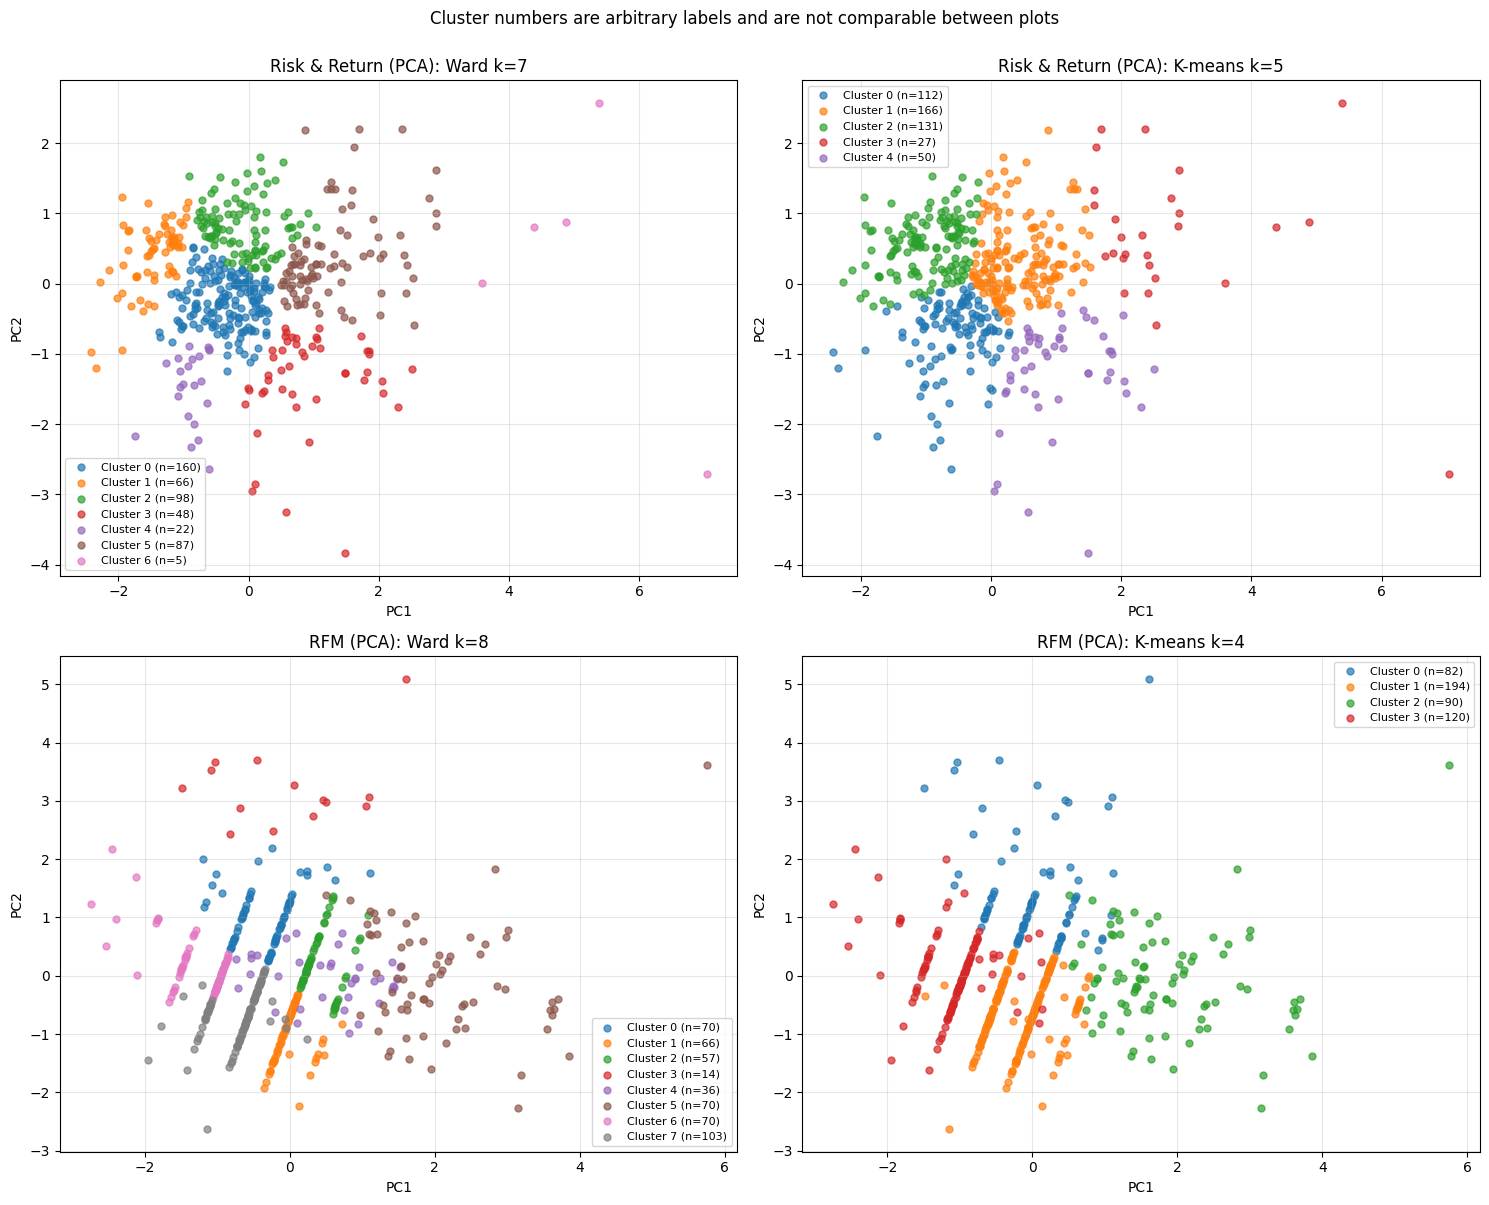

RR PCA:  PC1 = 62.54%, PC2 = 37.46%, total = 100.00%
RFM PCA: PC1 = 43.59%, PC2 = 33.65%, total = 77.24%


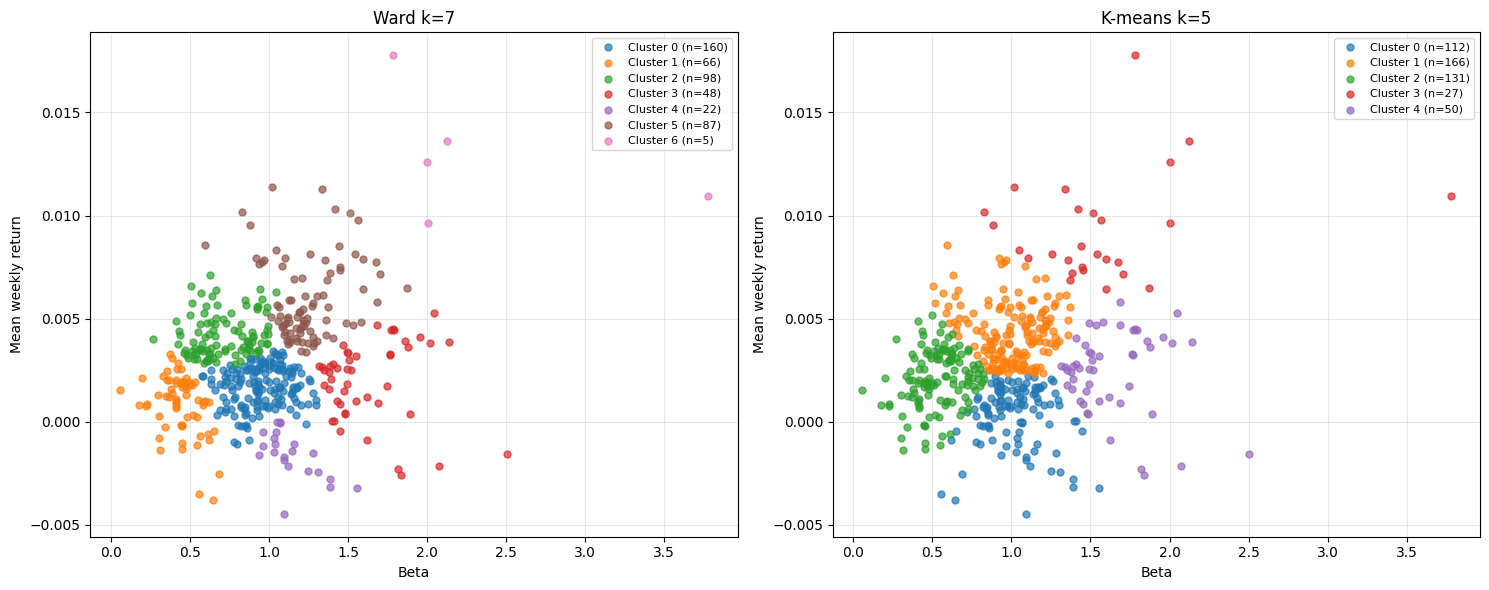

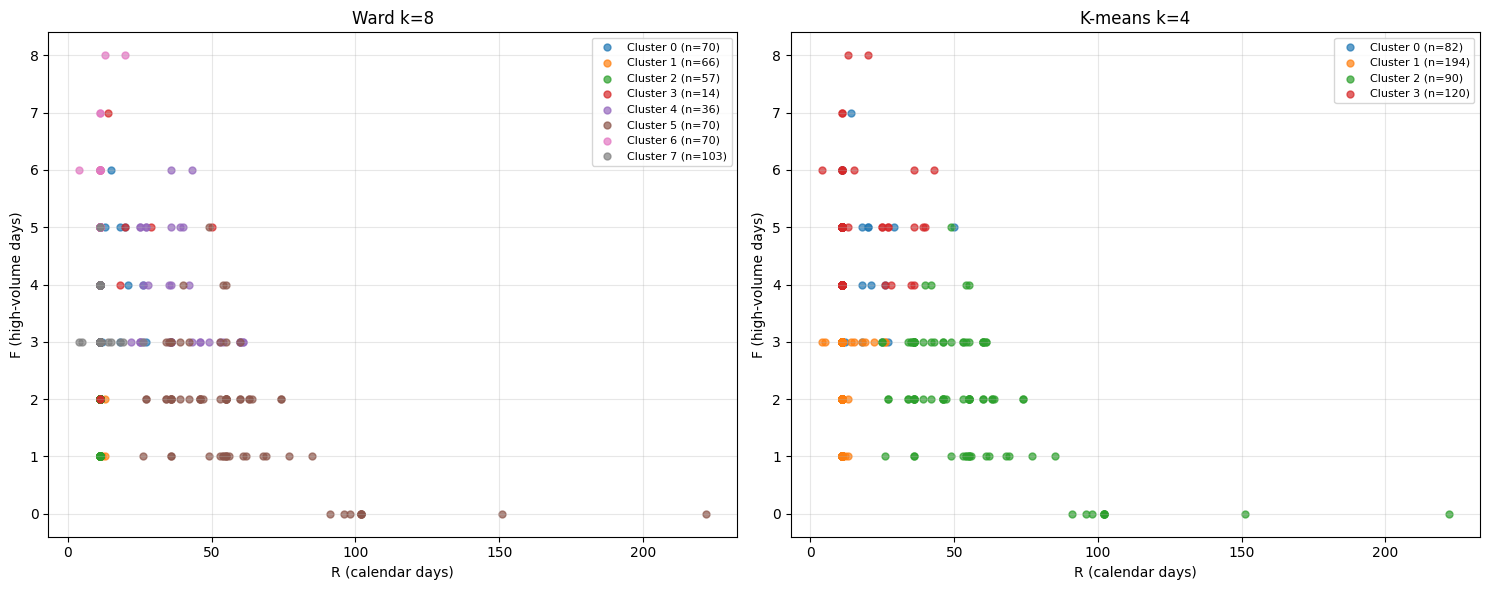

In [33]:
# Task 2.4 | Cell 33: labelled 2D visualisations
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_rr = PCA(n_components=2, random_state=SEED)
Z_rr_pca = pca_rr.fit_transform(Z_rr)
pca_rfm = PCA(n_components=2, random_state=SEED)
Z_rfm_pca = pca_rfm.fit_transform(Z_rfm)

def plot_clusters(ax, x, y, labels, title, xlabel, ylabel):
    """Scatter with one legend entry per cluster (labels are arbitrary numbers)."""
    labels = np.asarray(labels)
    cmap = plt.get_cmap("tab10")
    for i, c in enumerate(sorted(np.unique(labels))):
        mask = labels == c
        ax.scatter(np.asarray(x)[mask], np.asarray(y)[mask], s=25, alpha=0.7,
                   color=cmap(i % 10), label=f"Cluster {c} (n={mask.sum()})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(15, 12))
plot_clusters(axes[0, 0], Z_rr_pca[:, 0], Z_rr_pca[:, 1], feature_table["Ward_RR"],
              f"Risk & Return (PCA): Ward k={k_rr_ward}", "PC1", "PC2")
plot_clusters(axes[0, 1], Z_rr_pca[:, 0], Z_rr_pca[:, 1], feature_table["KM_RR"],
              f"Risk & Return (PCA): K-means k={k_rr_km}", "PC1", "PC2")
plot_clusters(axes[1, 0], Z_rfm_pca[:, 0], Z_rfm_pca[:, 1], feature_table["Ward_RFM"],
              f"RFM (PCA): Ward k={k_rfm_ward}", "PC1", "PC2")
plot_clusters(axes[1, 1], Z_rfm_pca[:, 0], Z_rfm_pca[:, 1], feature_table["KM_RFM"],
              f"RFM (PCA): K-means k={k_rfm_km}", "PC1", "PC2")
plt.suptitle("Cluster numbers are arbitrary labels and are not comparable between plots", y=1.0)
plt.tight_layout()
plt.show()

ev_rr = pca_rr.explained_variance_ratio_
ev_rfm = pca_rfm.explained_variance_ratio_
print(f"RR PCA:  PC1 = {ev_rr[0]:.2%}, PC2 = {ev_rr[1]:.2%}, total = {ev_rr.sum():.2%}")
print(f"RFM PCA: PC1 = {ev_rfm[0]:.2%}, PC2 = {ev_rfm[1]:.2%}, total = {ev_rfm.sum():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_clusters(axes[0], feature_table["Beta"], feature_table["Mean_Weekly_Return"],
              feature_table["Ward_RR"], f"Ward k={k_rr_ward}", "Beta", "Mean weekly return")
plot_clusters(axes[1], feature_table["Beta"], feature_table["Mean_Weekly_Return"],
              feature_table["KM_RR"], f"K-means k={k_rr_km}", "Beta", "Mean weekly return")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_clusters(axes[0], feature_table["R"], feature_table["F"], feature_table["Ward_RFM"],
              f"Ward k={k_rfm_ward}", "R (calendar days)", "F (high-volume days)")
plot_clusters(axes[1], feature_table["R"], feature_table["F"], feature_table["KM_RFM"],
              f"K-means k={k_rfm_km}", "R (calendar days)", "F (high-volume days)")
plt.tight_layout()
plt.show()

In [34]:

# Task 2.4 | Cell 34: agreement between algorithms and final profiles

from sklearn.metrics import adjusted_rand_score


ari_rr = adjusted_rand_score(
    feature_table["Ward_RR"],
    feature_table["KM_RR"]
)

ari_rfm = adjusted_rand_score(
    feature_table["Ward_RFM"],
    feature_table["KM_RFM"]
)

print("ARI risk/return:", round(ari_rr, 3))
print("ARI RFM:", round(ari_rfm, 3))


rr_features = ["Mean_Weekly_Return", "Beta"]
rfm_features = ["R", "F", "M"]

for label_col, feats in [
    ("Ward_RR", rr_features),
    ("KM_RR", rr_features),
    ("Ward_RFM", rfm_features),
    ("KM_RFM", rfm_features)
]:

    print("\n" + "=" * 55)
    print(label_col)
    print("=" * 55)

    print("\nCluster sizes:")
    cluster_sizes = feature_table[label_col].value_counts().sort_index()
    print(cluster_sizes)

    print("\nCluster means:")
    cluster_means = feature_table.groupby(label_col)[feats].mean()
    display(cluster_means.round(4))

    print("\nCluster medians:")
    cluster_medians = feature_table.groupby(label_col)[feats].median()
    display(cluster_medians.round(4))

    print("\nTickers in clusters with 20 shares or fewer:")

    small_clusters = cluster_sizes[cluster_sizes <= 20].index

    if len(small_clusters) == 0:
        print("No clusters with 20 shares or fewer.")
    else:
        for cluster in small_clusters:
            tickers = feature_table.index[
                feature_table[label_col] == cluster
            ].tolist()

            print(
                "Cluster", cluster,
                "| Size:", len(tickers),
                "| Tickers:", tickers
            )

ARI risk/return: 0.29
ARI RFM: 0.396

Ward_RR

Cluster sizes:
Ward_RR
0    160
1     66
2     98
3     48
4     22
5     87
6      5
Name: count, dtype: int64

Cluster means:


,Mean_Weekly_Return,Beta
Ward_RR,,
0,0.0017,0.9499
1,0.0009,0.4390
2,0.0042,0.7104
3,0.0020,1.6280
4,-0.0016,1.1397
5,0.0059,1.2383
6,0.0129,2.3386



Cluster medians:


,Mean_Weekly_Return,Beta
Ward_RR,,
0,0.0018,0.9363
1,0.0011,0.4485
2,0.0039,0.6663
3,0.0025,1.5139
4,-0.0015,1.0926
5,0.0053,1.2103
6,0.0126,2.0032



Tickers in clusters with 20 shares or fewer:
Cluster 6 | Size: 5 | Tickers: ['CVNA', 'NVDA', 'PLTR', 'SMCI', 'VRT']

KM_RR

Cluster sizes:
KM_RR
0    112
1    166
2    131
3     27
4     50
Name: count, dtype: int64

Cluster means:


,Mean_Weekly_Return,Beta
KM_RR,,
0,0.0003,1.0200
1,0.0043,0.9964
2,0.0021,0.5335
3,0.0093,1.5595
4,0.0024,1.6315


... (7 outputs left out)

,R,F,M
KM_RFM,,,
0,12.8902,3.2561,1.248581e+11
1,11.2835,2.3608,1.500737e+10
2,56.2444,2.0222,4.694648e+10
3,13.4167,4.5500,1.479553e+10



Cluster medians:


,R,F,M
KM_RFM,,,
0,11.0,3.0,6.395792e+10
1,11.0,2.0,1.310477e+10
2,53.5,2.0,2.145008e+10
3,11.0,4.0,1.274104e+10



Tickers in clusters with 20 shares or fewer:
No clusters with 20 shares or fewer.


In [35]:
# Task 2.5.1 | Cell 35: correlations among R, F and log1p(M)

corr_data = feature_table[["R", "F"]].copy()

corr_data["log1p_M"] = np.log1p(feature_table["M"])

corr_raw = corr_data.corr()

print("Correlations (R in original units):")
display(corr_raw.round(2))


corr_model = X_rfm.rename(columns={"M": "log1p_M"}).corr()

print("Correlations (inputs actually clustered: log1p(R), F, log1p(M)):")
display(corr_model.round(2))

Correlations (R in original units):


,R,F,log1p_M
R,1.00,-0.35,0.15
F,-0.35,1.00,0.01
log1p_M,0.15,0.01,1.00


Correlations (inputs actually clustered: log1p(R), F, log1p(M)):


,R,F,log1p_M
R,1.00,-0.29,0.13
F,-0.29,1.00,0.01
log1p_M,0.13,0.01,1.00


In [36]:
# Task 2.5.2 | Cell 36: Ward on R and F only

X_rf = X_rfm[["R", "F"]].copy()

assert X_rf.index.equals(feature_table.index)

scaler_rf = StandardScaler()

Z_rf = pd.DataFrame(
    scaler_rf.fit_transform(X_rf),
    index=X_rf.index,
    columns=X_rf.columns
)

link_rf = linkage(Z_rf, method="ward")

labels_rf = cut_tree(link_rf, n_clusters=k_rfm_ward).ravel().astype(int)

feature_table["Ward_RF_only"] = labels_rf

print("Cluster sizes after removing Monetary:")
print(feature_table["Ward_RF_only"].value_counts().sort_index())

Cluster sizes after removing Monetary:
Ward_RF_only
0     83
1    125
2    123
3     20
4     32
5     47
6     46
7     10
Name: count, dtype: int64


In [37]:
# Task 2.5.2 | Cell 37: effect of removing M

ari_removal = adjusted_rand_score(
    feature_table["Ward_RFM"],
    feature_table["Ward_RF_only"]
)

print("ARI (with M vs without M):", round(ari_removal, 3))


print("\nCluster membership comparison:")
display(
    pd.crosstab(
        feature_table["Ward_RFM"],
        feature_table["Ward_RF_only"],
        margins=True
    )
)


print("\nMonetary (M) profiles - Original Ward RFM:")

m_profile_rfm = feature_table.groupby("Ward_RFM").agg({
    "M": ["size", "mean", "median"]
})
m_profile_rfm.columns = ["Cluster_Size", "Mean_M", "Median_M"]

display(m_profile_rfm.round(2))


print("\nMonetary (M) profiles - Ward R and F only:")

m_profile_rf = feature_table.groupby("Ward_RF_only").agg({
    "M": ["size", "mean", "median"]
})
m_profile_rf.columns = ["Cluster_Size", "Mean_M", "Median_M"]

display(m_profile_rf.round(2))


print("\nR and F profiles - Ward R and F only:")

rf_profile = feature_table.groupby("Ward_RF_only").agg({
    "R": ["size", "mean", "median"],
    "F": ["mean", "median"]
})
rf_profile.columns = ["Cluster_Size", "Mean_R", "Median_R", "Mean_F", "Median_F"]

display(rf_profile.round(2))

ARI (with M vs without M): 0.473

Cluster membership comparison:


Ward_RF_only,0,1,2,3,4,5,6,7,All
Ward_RFM,,,,,,,,,
0,23,0,37,4,0,0,6,0,70
1,0,66,0,0,0,0,0,0,66
2,0,57,0,0,0,0,0,0,57
3,1,2,1,4,0,0,6,0,14
4,0,0,5,11,20,0,0,0,36
5,0,0,0,1,12,47,0,10,70
6,38,0,0,0,0,0,32,0,70
7,21,0,80,0,0,0,2,0,103
All,83,125,123,20,32,47,46,10,486



Monetary (M) profiles - Original Ward RFM:


,Cluster_Size,Mean_M,Median_M
Ward_RFM,,,
0,70,5.040407e+10,4.460450e+10
1,66,1.085987e+10,1.067576e+10
2,57,4.240849e+10,3.236510e+10
3,14,4.255684e+11,3.037731e+11
4,36,1.570820e+10,1.490924e+10
5,70,5.558168e+10,2.502932e+10
6,70,1.471939e+10,1.376417e+10
7,103,1.013192e+10,8.851100e+09



Monetary (M) profiles - Ward R and F only:


,Cluster_Size,Mean_M,Median_M
Ward_RF_only,,,
0,83,2.098237e+10,1.377260e+10
1,125,3.433790e+10,1.769899e+10
2,123,2.811013e+10,1.473529e+10
3,20,1.577550e+11,2.022741e+10
4,32,2.517558e+10,1.768233e+10
5,47,2.847019e+10,2.084781e+10
6,46,5.136699e+10,1.617585e+10
7,10,1.997420e+11,2.378595e+10



R and F profiles - Ward R and F only:


,Cluster_Size,Mean_R,Median_R,Mean_F,Median_F
Ward_RF_only,,,,,
0,83,11.00,11.0,4.00,4.0
1,125,11.04,11.0,1.80,2.0
2,123,11.94,11.0,3.00,3.0
3,20,30.15,27.0,4.85,5.0
4,32,45.62,42.5,3.19,3.0
5,47,51.19,54.0,1.64,2.0
6,46,11.28,11.0,5.46,5.0
7,10,116.80,102.0,0.00,0.0


Task 3 - Business Intelligence and Critical Review

In [38]:
# Task 3.2.1 | Cell 38: sector composition of the final solutions

solutions = ["Ward_RR", "KM_RR", "Ward_RFM", "KM_RFM"]

sector_baseline = feature_table["Sector"].value_counts(normalize=True).sort_index()

print("Overall sector mix:")
display(sector_baseline.round(3))

sector_counts = {}
sector_percentages = {}

for sol in solutions:

    counts = (
        feature_table.groupby([sol, "Sector"])
        .size()
        .unstack(fill_value=0)
    )


    pct = (
        feature_table.groupby(sol)["Sector"]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
    )

    sector_counts[sol] = counts
    sector_percentages[sol] = pct

    print("\n" + "=" * 55)
    print(sol)
    print("=" * 55)

    display(counts)
    display((pct * 100).round(1))

Overall sector mix:


,proportion
Sector,
Communication Services,0.041
Consumer Discretionary,0.097
Consumer Staples,0.066
Energy,0.041
Financials,0.152
Health Care,0.119
Industrials,0.160
Information Technology,0.152
Materials,0.047



Ward_RR


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RR,,,,,,,,,,,
0,4,15,2,0,23,22,39,18,11,22,4
1,3,0,22,0,2,19,2,0,1,1,16
2,5,9,5,16,28,8,11,2,3,3,8
3,0,10,0,0,5,4,4,23,2,0,0
4,3,2,3,0,3,3,1,2,3,1,1
5,5,10,0,4,13,2,20,26,3,3,1
6,0,1,0,0,0,0,1,3,0,0,0


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RR,,,,,,,,,,,
0,2.5,9.4,1.2,0.0,14.4,13.8,24.4,11.2,6.9,13.8,2.5
1,4.5,0.0,33.3,0.0,3.0,28.8,3.0,0.0,1.5,1.5,24.2
2,5.1,9.2,5.1,16.3,28.6,8.2,11.2,2.0,3.1,3.1,8.2
3,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0
4,13.6,9.1,13.6,0.0,13.6,13.6,4.5,9.1,13.6,4.5,4.5
5,5.7,11.5,0.0,4.6,14.9,2.3,23.0,29.9,3.4,3.4,1.1
6,0.0,20.0,0.0,0.0,0.0,0.0,20.0,60.0,0.0,0.0,0.0



KM_RR


... (4 outputs left out)

Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
0,7.1,8.6,5.7,2.9,14.3,17.1,15.7,22.9,1.4,2.9,1.4
1,1.5,9.1,4.5,6.1,18.2,7.6,18.2,10.6,4.5,12.1,7.6
2,1.8,15.8,10.5,14.0,19.3,12.3,12.3,10.5,1.8,1.8,0.0
3,21.4,14.3,0.0,0.0,0.0,14.3,7.1,42.9,0.0,0.0,0.0
4,8.3,8.3,8.3,5.6,8.3,16.7,13.9,16.7,5.6,0.0,8.3
5,1.4,12.9,7.1,1.4,17.1,7.1,8.6,25.7,8.6,0.0,10.0
6,2.9,11.4,5.7,0.0,17.1,15.7,18.6,8.6,4.3,10.0,5.7
7,3.9,3.9,6.8,2.9,13.6,9.7,22.3,8.7,6.8,11.7,9.7



KM_RFM


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KM_RFM,,,,,,,,,,,
0,8,9,6,4,13,13,6,21,1,0,1
1,4,18,12,13,30,17,40,20,10,18,12
2,2,11,7,2,13,9,9,21,7,0,9
3,6,9,7,1,18,19,23,12,5,12,8


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KM_RFM,,,,,,,,,,,
0,9.8,11.0,7.3,4.9,15.9,15.9,7.3,25.6,1.2,0.0,1.2
1,2.1,9.3,6.2,6.7,15.5,8.8,20.6,10.3,5.2,9.3,6.2
2,2.2,12.2,7.8,2.2,14.4,10.0,10.0,23.3,7.8,0.0,10.0
3,5.0,7.5,5.8,0.8,15.0,15.8,19.2,10.0,4.2,10.0,6.7


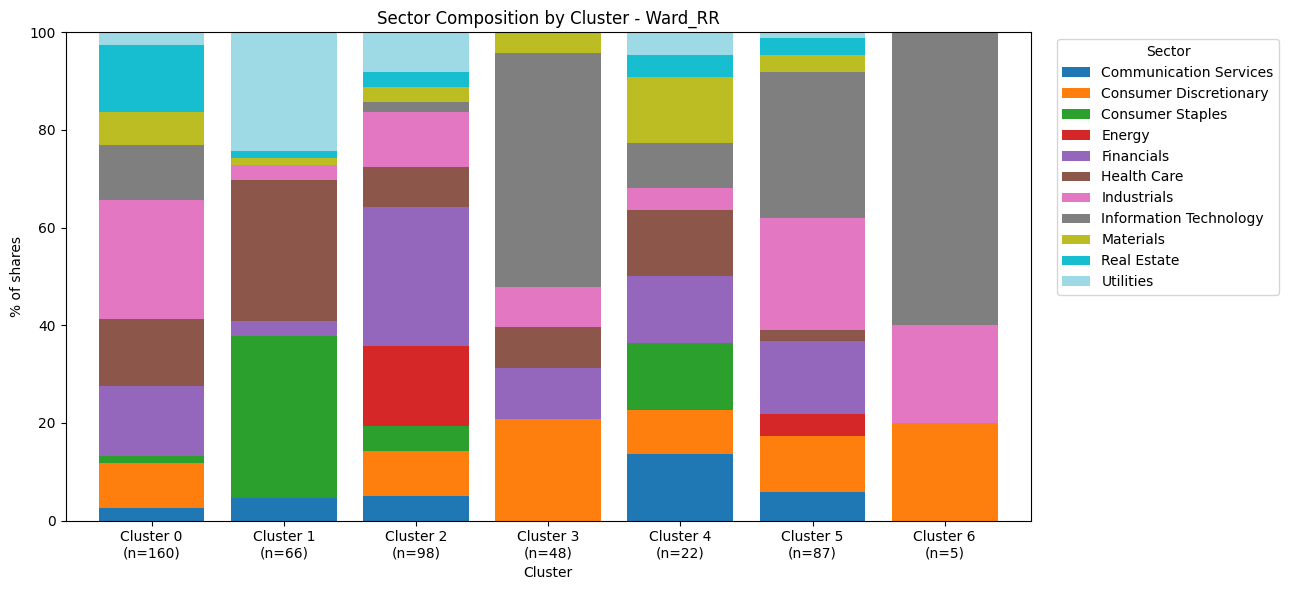

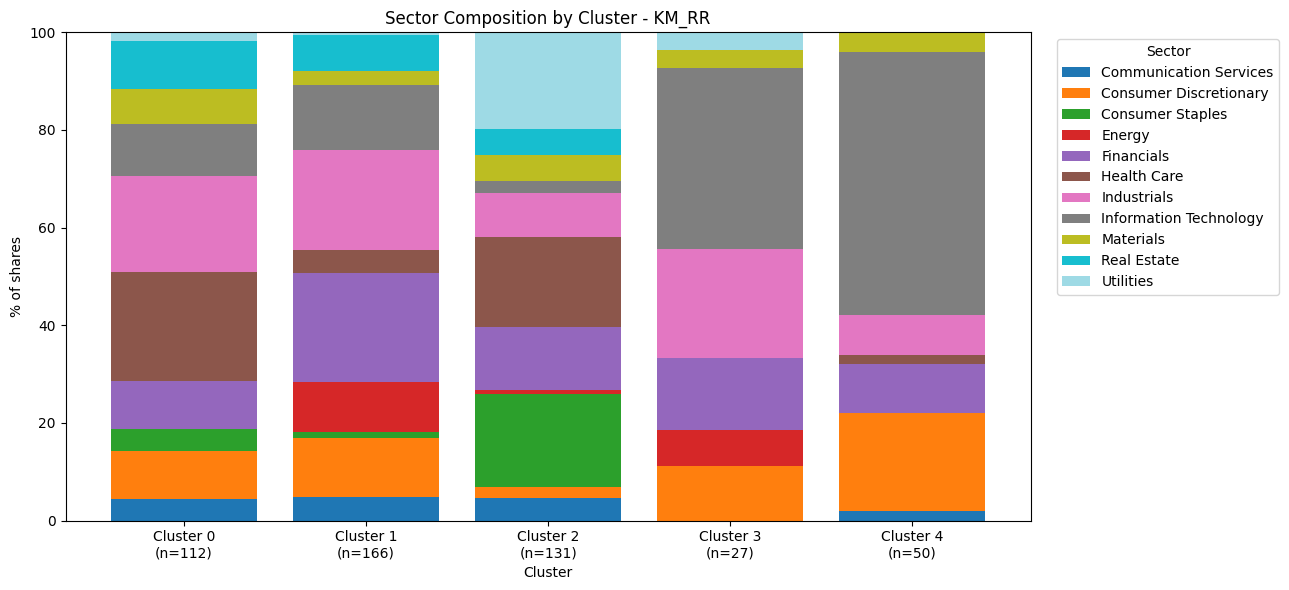

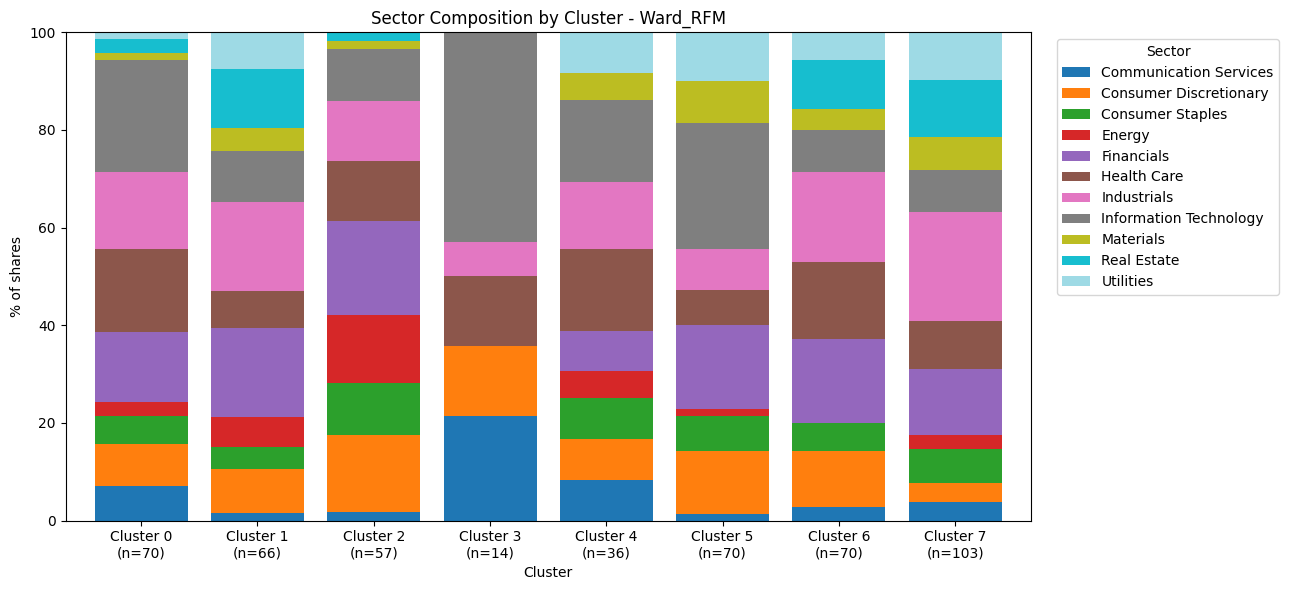

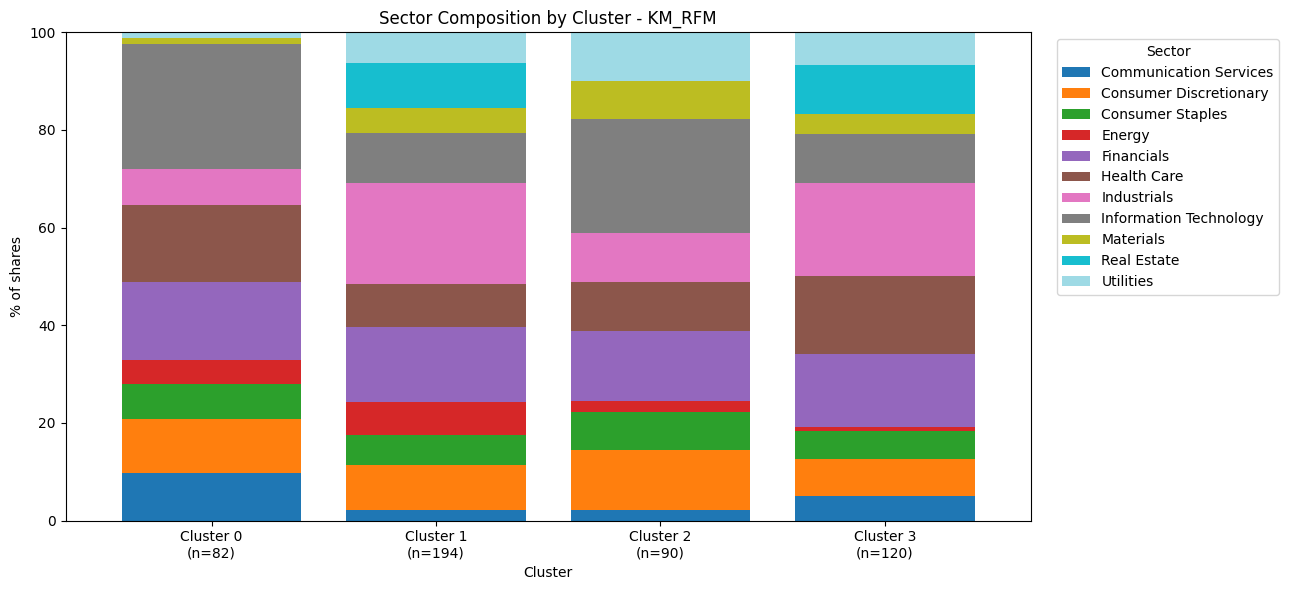

In [39]:
# Task 3.2.1 | Cell 39: stacked bar charts of sector mix per cluster

import matplotlib.pyplot as plt

for sol in solutions:

    pct = sector_percentages[sol] * 100

    cluster_sizes = feature_table[sol].value_counts().sort_index()

    tick_labels = [
        f"Cluster {cluster}\n(n={cluster_sizes.loc[cluster]})"
        for cluster in pct.index
    ]

    fig, ax = plt.subplots(figsize=(13, 6))

    pct.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        width=0.8,
        colormap="tab20"
    )

    ax.set_title(f"Sector Composition by Cluster - {sol}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("% of shares")
    ax.set_ylim(0, 100)

    ax.set_xticklabels(tick_labels, rotation=0)

    ax.legend(
        title="Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

In [40]:
# Task 3.2.1 | Cell 40: risk/return clusters vs RFM clusters

from sklearn.metrics import adjusted_rand_score

overlap = (
    feature_table.groupby(["Ward_RR", "Ward_RFM"])
    .size()
    .unstack(fill_value=0)
)

print("Overlap between Ward risk/return and Ward RFM clusters:")
display(overlap)

ari_rr_vs_rfm = adjusted_rand_score(
    feature_table["Ward_RR"],
    feature_table["Ward_RFM"]
)

print(
    "ARI (risk/return clusters vs RFM clusters):",
    round(ari_rr_vs_rfm, 3)
)

overlap_km = (
    feature_table.groupby(["KM_RR", "KM_RFM"])
    .size()
    .unstack(fill_value=0)
)

print("\nOverlap between K-means risk/return and K-means RFM clusters:")
display(overlap_km)

ari_km_rr_vs_rfm = adjusted_rand_score(
    feature_table["KM_RR"],
    feature_table["KM_RFM"]
)

print(
    "K-means ARI (risk/return vs RFM):",
    round(ari_km_rr_vs_rfm, 3)
)

Overlap between Ward risk/return and Ward RFM clusters:


Ward_RFM,0,1,2,3,4,5,6,7
Ward_RR,,,,,,,,
0,16,29,12,1,8,19,24,51
1,11,5,9,1,4,14,9,13
2,10,17,22,0,6,9,13,21
3,12,6,4,3,5,9,5,4
4,3,2,2,0,5,2,4,4
5,18,7,8,7,8,14,15,10
6,0,0,0,2,0,3,0,0


ARI (risk/return clusters vs RFM clusters): 0.03

Overlap between K-means risk/return and K-means RFM clusters:


KM_RFM,0,1,2,3
KM_RR,,,,
0,11,49,22,30
1,26,76,23,41
2,26,47,24,34
3,5,8,8,6
4,14,14,13,9


K-means ARI (risk/return vs RFM): 0.014


In [41]:
# Task 3.2.1 | Cell 41: Ward profiles with sector mix

def profile_table(sol, features, scale=None):
    scale = scale or {}
    rows = []
    for cluster, group in feature_table.groupby(sol):
        row = {"Cluster": cluster, "Size": len(group)}
        for f in features:
            row[f"Median_{f}"] = group[f].median() / scale.get(f, 1)
        top = group["Sector"].value_counts(normalize=True).mul(100).round(1).head(2)
        row["Top_Sector_1"], row["Top_1_%"] = top.index[0], top.iloc[0]
        row["Top_Sector_2"] = top.index[1] if len(top) > 1 else "None"
        row["Top_2_%"] = top.iloc[1] if len(top) > 1 else 0.0
        rows.append(row)
    return pd.DataFrame(rows).set_index("Cluster")

print("Ward risk/return clusters:")
display(profile_table("Ward_RR", ["Mean_Weekly_Return", "Beta"]).round(4))

print("Ward RFM clusters (Median_M in USD billions):")
display(profile_table("Ward_RFM", ["R", "F", "M"], {"M": 1e9}).round(2))

import importlib.metadata as md
pkgs = ["pandas", "numpy", "yfinance", "scipy", "scikit-learn", "matplotlib", "lxml"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("requirements.txt", "w").write("\n".join(lines) + "\n")
print(open("requirements.txt").read())

Ward risk/return clusters:


,Size,Median_Mean_Weekly_Return,Median_Beta,Top_Sector_1,Top_1_%,Top_Sector_2,Top_2_%
Cluster,,,,,,,
0,160,0.0018,0.9363,Industrials,24.4,Financials,14.4
1,66,0.0011,0.4485,Consumer Staples,33.3,Health Care,28.8
2,98,0.0039,0.6663,Financials,28.6,Energy,16.3
3,48,0.0025,1.5139,Information Technology,47.9,Consumer Discretionary,20.8
4,22,-0.0015,1.0926,Communication Services,13.6,Materials,13.6
5,87,0.0053,1.2103,Information Technology,29.9,Industrials,23.0
6,5,0.0126,2.0032,Information Technology,60.0,Consumer Discretionary,20.0


Ward RFM clusters (Median_M in USD billions):


,Size,Median_R,Median_F,Median_M,Top_Sector_1,Top_1_%,Top_Sector_2,Top_2_%
Cluster,,,,,,,,
0,70,11.0,3.0,44.60,Information Technology,22.9,Health Care,17.1
1,66,11.0,2.0,10.68,Industrials,18.2,Financials,18.2
2,57,11.0,2.0,32.37,Financials,19.3,Consumer Discretionary,15.8
3,14,11.0,5.0,303.77,Information Technology,42.9,Communication Services,21.4
4,36,36.0,3.0,14.91,Information Technology,16.7,Health Care,16.7
5,70,55.0,2.0,25.03,Information Technology,25.7,Financials,17.1
6,70,11.0,4.0,13.76,Industrials,18.6,Financials,17.1
7,103,11.0,3.0,8.85,Industrials,22.3,Financials,13.6


pandas==2.2.3
numpy==2.4.6
yfinance==0.2.66
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
lxml==6.1.3

